# Probing del MLP por cabeza de atención — atributos de AwA2 (2026-11-02)

**Pregunta.** Ya probamos qué atributos de AwA2 se pueden leer de la **salida de cada cabeza** (`probing_awa2.ipynb`). Ahora: **después de que el MLP del bloque procesa lo que aportó cada cabeza, ¿se lee más, menos o distinto?** Es decir, ¿el MLP "refina" lo que escribió cada cabeza?

## El problema: el MLP no es "por cabeza"
En el último bloque (bloque 4) el flujo es:

```
x  ─────────────────────────────┐   x      = estado del token [CLS] que entra al bloque (48 dim)
x → LN1 → 4 cabezas → W_O ──────┼─► a = x + Σ_h c_h + b_O        c_h = W_O[:, cabeza h] · z_h   (z_h = salida de la cabeza h, 12 dim)
a ───────────────────────────────┤
a → LN2 → dense_1 → GELU → dense_2 → m = MLP(a)                    (el MLP recibe la SUMA de las 4 cabezas)
salida del bloque = a + m
```

El MLP recibe **una sola entrada que mezcla las 4 cabezas** y además es no lineal (LayerNorm + GELU), así que su salida **no se puede partir exactamente en cuatro trozos, uno por cabeza**. Hay que definir qué significa "el MLP de la cabeza h". Uso dos definiciones contrafactuales, que responden preguntas distintas:

| Representación | Definición | Pregunta que responde |
|---|---|---|
| **`mlp_solo_h`** | `MLP( x + c_h + b_O )`: el MLP alimentado **solo con la cabeza h** (las otras tres apagadas) | ¿Qué hace el MLP con *lo que esa cabeza escribe*, sin ayuda de las otras? |
| **`mlp_loo_h`** | `MLP(a) − MLP(a − c_h)`: lo que **cambia** la salida del MLP al quitar la cabeza h del conjunto (*leave-one-out*) | ¿Cuánto del resultado final del MLP **depende** de la cabeza h, en contexto normal? |

Como referencias:
- **`cabeza`**: la salida cruda de la cabeza (12 dim) — es lo que ya sondeó `probing_awa2.ipynb`, aquí recalculado con los mismos folds para que sea comparable.
- **`mlp_completo`**: `MLP(a)`, el MLP con las 4 cabezas (igual para todas las cabezas; es el techo de referencia).

> **Advertencia importante de interpretación.** Una sonda sobre `mlp_solo_h` mide dos cosas mezcladas: lo que la cabeza escribe y lo que hace el MLP con eso *fuera de su condiciones normales* (nunca ve una entrada con una sola cabeza). Por eso `mlp_loo_h` es la medida más fiel a "lo que usa el modelo", y `mlp_solo_h` es una comparación más simple. Si ambas dicen lo mismo, la conclusión es sólida.

## Cómo se prueba (igual que en el probing por cabeza)
- Datos: test de AwA2 (7 468 imágenes, 50 clases), solo el token [CLS] del bloque 4.
- Objetivos: los 47 atributos visuales de AwA2 (continuos, constantes por clase).
- Sonda: Ridge lineal con `alpha` elegido por atributo, **R² fuera de muestra** con 5 folds estratificados por clase.
- **Nulo por permutación de clases** (100 permutaciones): se baraja qué fila de atributos le toca a cada clase; conserva la distribución de cada atributo pero rompe su relación con la imagen. **Selectividad = R² real − media del R² nulo.**
- Agrupación por origen visual (color, textura, forma, partes del cuerpo = *animal*; hábitat = *fondo*), igual que en `attribute_groups_entropy.ipynb`.

> **Limitación heredada:** los atributos son por clase, así que un atributo de hábitat como `ocean` se puede predecir reconociendo a una foca. R² alto en `ocean` no prueba que alguien lea el fondo.

## 0. Configuración

In [1]:
# ======================================================================
MODEL_KEY = "entropy_l001"     # modelo principal: λ_entropy = 0.01
REFERENCE = "unconstrained"    # modelo de comparación sin penalizar
MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
    "entropy_l01": "vit-15-entropy_l01-s0-AwA2",
    "entropy_l001": "vit-15-entropy_l001-s0-AwA2",
    "entropy_l0001": "vit-15-entropy_l0001-s0-AwA2",
}
PROBE_MODELS = [MODEL_KEY, REFERENCE]     # modelos que se sondean aquí (el nulo es lo caro; añade más si quieres)
BLOCK_IDX = 4        # bloque (1-indexado) que se analiza
N_PERM = 100         # permutaciones de clase para el nulo
N_FOLDS = 5
SEED = 0

GROUPS = {
    "color":   ["black", "white", "blue", "brown", "gray", "orange", "red", "yellow"],
    "textura": ["patches", "spots", "stripes", "furry", "hairless", "toughskin"],
    "forma":   ["big", "small", "bulbous", "lean"],
    "partes":  ["flippers", "hands", "hooves", "pads", "paws", "longleg", "longneck", "tail",
                "chewteeth", "meatteeth", "buckteeth", "strainteeth", "horns", "claws", "tusks"],
    "hábitat": ["arctic", "coastal", "desert", "bush", "plains", "forest", "fields", "jungle",
                "mountains", "ocean", "ground", "water", "tree", "cave"],
}
ANIMAL = [a for g in ("color", "textura", "forma", "partes") for a in GROUPS[g]]
FONDO = GROUPS["hábitat"]
# ======================================================================

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.datasets import AwA2Dataset
from modules.figures import save_fig
from modules.model import ViTForClassfication

torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
PROBING_DIR = EXPERIMENTS_DIR / "25092026_awa2_probing_entropy"            # el probing por cabeza ya hecho (para atributos y orden)
OUTPUT_DIR = EXPERIMENTS_DIR / "02112026_mlp_per_head_probing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("device:", device, "| modelos a sondear:", PROBE_MODELS)

/home/claude/work/ennv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/02 16:22:30 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/claude/work/ennv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


device: cpu | modelos a sondear: ['entropy_l001', 'unconstrained']


## 1. Datos y matriz clase × atributo

Se usan los mismos 47 atributos y el mismo orden que el probing previo (se leen de su CSV de R², para que ambas tablas se puedan comparar columna a columna).

In [2]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
labels = dataset.testset.labels.numpy()          # clase de cada imagen de test
n_cls = len(classes)

attr_names = list(pd.read_csv(PROBING_DIR / f"r2_{MODEL_KEY}_block{BLOCK_IDX}_cls_visual.csv", index_col=0).columns)
n_attr = len(attr_names)
A = {a: i for i, a in enumerate(attr_names)}
assert set(attr_names) == set(ANIMAL) | set(FONDO)

cols = [list(dataset.attribute_names).index(a) for a in attr_names]
Y = dataset.attributes_continuous[labels].numpy()[:, cols]      # (N, 47): atributos de la clase de cada imagen
class_attr = np.zeros((n_cls, n_attr)); class_attr[labels] = Y    # (50, 47): una fila por clase (para barajar en el nulo)
print(f"{len(labels)} imágenes de test | {n_cls} clases | {n_attr} atributos ({len(ANIMAL)} animal, {len(FONDO)} fondo)")

7468 imágenes de test | 50 clases | 47 atributos (33 animal, 14 fondo)


## 2. Extraer las representaciones del bloque 4

Con *hooks* de PyTorch capturamos, sin modificar el modelo:
1. `x`: lo que **entra** al bloque 4 (para cada token; usamos el del [CLS]).
2. `z`: la salida de las 4 cabezas **antes** de la proyección `W_O` (48 = 4 cabezas × 12; el trozo `[12h : 12h+12]` es la cabeza h).
3. la salida del bloque, solo para **verificar** que nuestra reconstrucción manual es exacta.

Luego rehacemos a mano el bloque para el token [CLS] y calculamos las cuatro representaciones de la tabla de arriba. La comprobación `assert` falla si la reconstrucción no coincide con el modelo real (tolerancia 1e-4).

In [3]:
@torch.no_grad()
def extract(model):
    """Para todo el test devuelve un dict de arreglos numpy con las representaciones del [CLS] en el bloque BLOCK_IDX."""
    blk = model.encoder.blocks[BLOCK_IDX - 1]
    H = blk.attention.num_attention_heads
    hs = blk.attention.attention_head_size            # 12
    W_O, b_O = blk.attention.output_projection.weight, blk.attention.output_projection.bias   # (48,48), (48,)
    mlp = lambda v: blk.mlp(blk.layernorm_2(v))        # el MLP del bloque, con su LayerNorm previo (pre-LN)

    cap = {}
    h1 = blk.register_forward_pre_hook(lambda m, args: cap.__setitem__("x", args[0]))                          # entrada del bloque
    h2 = blk.attention.output_projection.register_forward_pre_hook(lambda m, args: cap.__setitem__("z", args[0]))   # cabezas concatenadas
    h3 = blk.register_forward_hook(lambda m, args, out: cap.__setitem__("out", out[0]))                         # salida del bloque
    R = {"cabeza": [], "mlp_solo": [], "mlp_loo": [], "mlp_completo": []}
    try:
        for images, _, _ in testloader:
            model(images.to(device))
            x0 = cap["x"][:, 0]                         # (B, 48)  token [CLS] que entra
            z = cap["z"][:, 0]                          # (B, 48)  salida de las cabezas para el [CLS]
            c = [z[:, h * hs:(h + 1) * hs] @ W_O[:, h * hs:(h + 1) * hs].T for h in range(H)]   # aporte de cada cabeza al residual
            a = x0 + sum(c) + b_O                       # estado tras la atención (lo que recibe el MLP)
            m_full = mlp(a)
            # --- verificación: a + MLP(a) debe ser exactamente la salida del bloque ---
            assert torch.allclose(a + m_full, cap["out"][:, 0], atol=1e-4), "la reconstrucción manual no coincide con el modelo"
            R["cabeza"].append(torch.stack([z[:, h * hs:(h + 1) * hs] for h in range(H)], 1).cpu())             # (B, 4, 12)
            R["mlp_solo"].append(torch.stack([mlp(x0 + c[h] + b_O) for h in range(H)], 1).cpu())                # (B, 4, 48) solo cabeza h
            R["mlp_loo"].append(torch.stack([m_full - mlp(a - c[h]) for h in range(H)], 1).cpu())              # (B, 4, 48) efecto de quitar h
            R["mlp_completo"].append(m_full.unsqueeze(1).repeat(1, H, 1).cpu())                                # (B, 4, 48) igual para todas
    finally:
        for h in (h1, h2, h3):
            h.remove()
    return {k: torch.cat(v).numpy() for k, v in R.items()}


def load_model(name):
    exp = EXPERIMENTS_DIR / name
    m = ViTForClassfication(json.loads((exp / "config.json").read_text()))
    m.load_state_dict(torch.load(exp / "model_final.pt", map_location="cpu"))
    return m.to(device).eval()


FEATS = {}
for key in PROBE_MODELS:
    FEATS[key] = extract(load_model(MODELS[key]))
    print(key, {k: v.shape for k, v in FEATS[key].items()}, "-> reconstrucción verificada")

entropy_l001 {'cabeza': (7468, 4, 12), 'mlp_solo': (7468, 4, 48), 'mlp_loo': (7468, 4, 48), 'mlp_completo': (7468, 4, 48)} -> reconstrucción verificada


unconstrained {'cabeza': (7468, 4, 12), 'mlp_solo': (7468, 4, 48), 'mlp_loo': (7468, 4, 48), 'mlp_completo': (7468, 4, 48)} -> reconstrucción verificada


## 3. Sonda lineal y nulo por permutación

`probe_r2` entrena un Ridge por fold y devuelve el R² fuera de muestra para cada uno de los 47 atributos. Para el nulo se repite lo mismo, pero con `class_attr` barajado por filas (las 50 clases reciben los atributos de otra clase), 100 veces. **Esta es la celda lenta** (varios minutos): son 2 modelos × 3 representaciones × 4 cabezas × 100 permutaciones × 5 folds.

In [4]:
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(labels, labels))


def probe_r2(X, Yt):
    """R² fuera de muestra por atributo. X: (N, d) representación; Yt: (N, 47) atributos."""
    pred = np.zeros_like(Yt)
    for tr, te in folds:
        # StandardScaler: pone cada dimensión en la misma escala; RidgeCV elige la regularización por atributo
        sonda = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13), alpha_per_target=True))
        pred[te] = sonda.fit(X[tr], Yt[tr]).predict(X[te])
    return r2_score(Yt, pred, multioutput="raw_values")


rng = np.random.default_rng(SEED)
perms = [rng.permutation(n_cls) for _ in range(N_PERM)]       # la MISMA lista de permutaciones para todas las representaciones
REPS = ["cabeza", "mlp_solo", "mlp_loo", "mlp_completo"]
H = 4
R2, NULL = {}, {}                                            # R2[(modelo, rep)] -> (4, 47) ; NULL[...] -> (N_PERM, 4, 47)
for key in PROBE_MODELS:
    for rep in REPS:
        # mlp_completo es idéntico para las 4 cabezas: se sondea una vez y se repite
        heads = [0] if rep == "mlp_completo" else range(H)
        r, n = np.zeros((H, n_attr)), np.zeros((N_PERM, H, n_attr))
        for h in heads:
            X = FEATS[key][rep][:, h]
            r[h] = probe_r2(X, Y)
            for p, perm in enumerate(perms):
                n[p, h] = probe_r2(X, class_attr[perm][labels])
        if rep == "mlp_completo":
            r[:], n[:] = r[0], n[:, :1, :]
        R2[(key, rep)], NULL[(key, rep)] = r, n
        print(f"{key:>14} | {rep:<13} R² medio = {r.mean():.3f} | nulo medio = {n.mean():.3f}", flush=True)
np.savez_compressed(OUTPUT_DIR / "r2_and_null.npz", **{f"r2__{k[0]}__{k[1]}": v for k, v in R2.items()},
                    **{f"null__{k[0]}__{k[1]}": v for k, v in NULL.items()}, attrs=np.array(attr_names))

  entropy_l001 | cabeza        R² medio = 0.061 | nulo medio = 0.022


  entropy_l001 | mlp_solo      R² medio = 0.076 | nulo medio = 0.031


  entropy_l001 | mlp_loo       R² medio = 0.043 | nulo medio = 0.016


  entropy_l001 | mlp_completo  R² medio = 0.081 | nulo medio = 0.035


 unconstrained | cabeza        R² medio = 0.076 | nulo medio = 0.024


 unconstrained | mlp_solo      R² medio = 0.119 | nulo medio = 0.044


 unconstrained | mlp_loo       R² medio = 0.081 | nulo medio = 0.025


 unconstrained | mlp_completo  R² medio = 0.131 | nulo medio = 0.048


## 4. Resultados

### 4.1 R² medio por cabeza y representación
Cada celda es el R² medio sobre los 47 atributos. Si `mlp_*` > `cabeza`, el MLP hace *más legible* lo que escribió la cabeza; si es menor, lo hace menos legible (o lo mezcla). La fila `nulo` es el R² medio de las permutaciones (≈ lo que se saca por puro azar de capacidad de la sonda).

In [5]:
filas = []
for key in PROBE_MODELS:
    for rep in REPS:
        r, n = R2[(key, rep)], NULL[(key, rep)]
        for h in range(H):
            nulo_h = n[:, h].mean(1) if rep != "mlp_completo" else n[:, 0].mean(1)
            filas.append({"modelo": key, "representación": rep, "cabeza": f"head {h + 1}", "R² medio": r[h].mean(),
                          "nulo medio": nulo_h.mean(), "selectividad": r[h].mean() - nulo_h.mean(),
                          "p (azar)": (1 + (nulo_h >= r[h].mean()).sum()) / (N_PERM + 1),
                          "atributos con R²>0.1": int((r[h] > 0.1).sum()), "R² máximo": r[h].max(),
                          "mejor atributo": attr_names[int(r[h].argmax())]})
RES = pd.DataFrame(filas)
RES.to_csv(OUTPUT_DIR / "mlp_probing_summary.csv", index=False)
for key in PROBE_MODELS:
    print(f"=== {key}: selectividad media (R² − nulo) ===")
    print(RES[RES.modelo == key].pivot(index="representación", columns="cabeza", values="selectividad").loc[REPS].round(3), "\n")
RES[RES.modelo == MODEL_KEY].round(3)

=== entropy_l001: selectividad media (R² − nulo) ===
cabeza          head 1  head 2  head 3  head 4
representación                                
cabeza           0.029   0.031   0.047   0.049
mlp_solo         0.047   0.044   0.043   0.046
mlp_loo          0.020   0.025   0.030   0.031
mlp_completo     0.046   0.046   0.046   0.046 

=== unconstrained: selectividad media (R² − nulo) ===
cabeza          head 1  head 2  head 3  head 4
representación                                
cabeza           0.047   0.064   0.052   0.046
mlp_solo         0.078   0.077   0.072   0.075
mlp_loo          0.059   0.071   0.050   0.048
mlp_completo     0.084   0.084   0.084   0.084 



,modelo,representación,cabeza,R² medio,nulo medio,selectividad,p (azar),atributos con R²>0.1,R² máximo,mejor atributo
0,entropy_l001,cabeza,head 1,0.050,0.021,0.029,0.01,1,0.118,ocean
1,entropy_l001,cabeza,head 2,0.052,0.021,0.031,0.01,2,0.114,ocean
2,entropy_l001,cabeza,head 3,0.071,0.024,0.047,0.01,8,0.237,ocean
3,entropy_l001,cabeza,head 4,0.071,0.021,0.049,0.01,7,0.196,ocean
4,entropy_l001,mlp_solo,head 1,0.079,0.032,0.047,0.01,8,0.240,ocean
5,entropy_l001,mlp_solo,head 2,0.075,0.031,0.044,0.01,8,0.230,ocean
6,entropy_l001,mlp_solo,head 3,0.074,0.031,0.043,0.01,8,0.216,ocean
7,entropy_l001,mlp_solo,head 4,0.077,0.031,0.046,0.01,8,0.242,ocean
8,entropy_l001,mlp_loo,head 1,0.037,0.017,0.020,0.01,0,0.074,ocean
9,entropy_l001,mlp_loo,head 2,0.042,0.016,0.025,0.01,6,0.147,ocean


guardado: experimentation/experiments/02112026_mlp_per_head_probing/r2_by_representation_entropy_l001.png


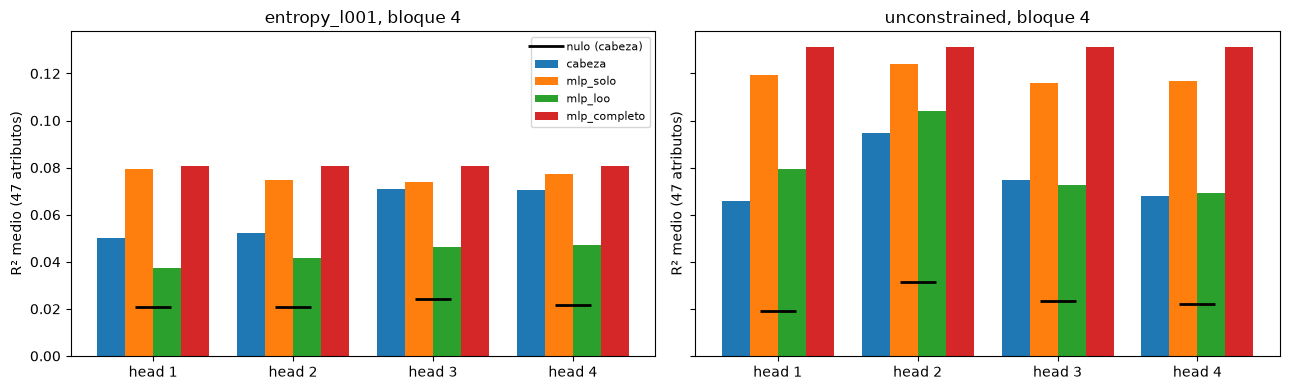

In [6]:
fig, axes = plt.subplots(1, len(PROBE_MODELS), figsize=(6.5 * len(PROBE_MODELS), 4), sharey=True)
ancho = 0.2
for ax, key in zip(np.atleast_1d(axes), PROBE_MODELS):
    for i, rep in enumerate(REPS):
        sub = RES[(RES.modelo == key) & (RES["representación"] == rep)]
        ax.bar(np.arange(H) + (i - 1.5) * ancho, sub["R² medio"], width=ancho, label=rep)
    nulo = RES[(RES.modelo == key) & (RES["representación"] == "cabeza")]["nulo medio"].values
    ax.plot(np.arange(H), nulo, "k_", ms=26, mew=2, label="nulo (cabeza)")
    ax.set_xticks(range(H)); ax.set_xticklabels([f"head {h + 1}" for h in range(H)])
    ax.set_title(f"{key}, bloque {BLOCK_IDX}"); ax.set_ylabel("R² medio (47 atributos)")
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "r2_by_representation", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()

### 4.2 ¿Qué hace el MLP con cada atributo? (ganancia = R²_MLP − R²_cabeza)
Un atributo con ganancia positiva se lee mejor *después* del MLP que en la salida cruda de la cabeza. Calculo la ganancia por cabeza y por grupo, para `mlp_solo` y `mlp_loo`. Las barras de abajo son el promedio por grupo.

guardado: experimentation/experiments/02112026_mlp_per_head_probing/gain_by_group_entropy_l001.png


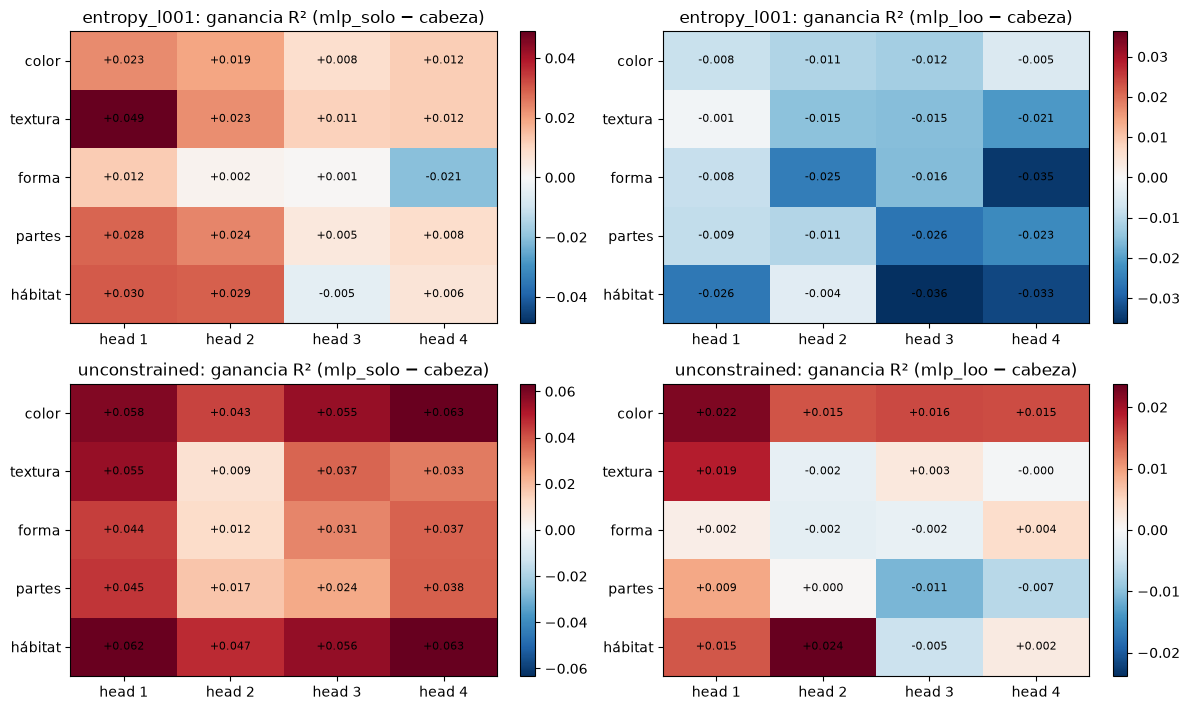

In [7]:
fig, axes = plt.subplots(len(PROBE_MODELS), 2, figsize=(12, 3.6 * len(PROBE_MODELS)), squeeze=False)
tab = []
for r_i, key in enumerate(PROBE_MODELS):
    for c_i, rep in enumerate(["mlp_solo", "mlp_loo"]):
        gan = R2[(key, rep)] - R2[(key, "cabeza")]                      # (4, 47)
        M_ = np.array([[gan[h, [A[a] for a in GROUPS[g]]].mean() for h in range(H)] for g in GROUPS])   # (5 grupos, 4 cabezas)
        vm = np.abs(M_).max()
        ax = axes[r_i, c_i]
        im = ax.imshow(M_, cmap="RdBu_r", vmin=-vm, vmax=vm, aspect="auto")
        ax.set_xticks(range(H)); ax.set_xticklabels([f"head {h + 1}" for h in range(H)])
        ax.set_yticks(range(len(GROUPS))); ax.set_yticklabels(list(GROUPS))
        for i in range(M_.shape[0]):
            for j in range(M_.shape[1]):
                ax.text(j, i, f"{M_[i, j]:+.3f}", ha="center", va="center", fontsize=8)
        ax.set_title(f"{key}: ganancia R² ({rep} − cabeza)"); fig.colorbar(im, ax=ax, fraction=0.04)
        for g_i, g in enumerate(GROUPS):
            for h in range(H):
                tab.append({"modelo": key, "representación": rep, "grupo": g, "cabeza": f"head {h + 1}", "ganancia R²": M_[g_i, h]})
plt.tight_layout()
save_fig(fig, "gain_by_group", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()
pd.DataFrame(tab).to_csv(OUTPUT_DIR / "gain_by_group.csv", index=False)

### 4.3 Animal vs. fondo, ahora en las salidas del MLP
Mismo análisis de `attribute_groups_entropy.ipynb`: diferencia de R² entre los atributos de hábitat y los del animal, y cuánto de eso se espera por azar según el nulo (`exceso`). Si el MLP "amplifica" el fondo, el exceso sube respecto a `cabeza`.

In [8]:
ia, ifo = [A[a] for a in ANIMAL], [A[a] for a in FONDO]
filas = []
for key in PROBE_MODELS:
    for rep in REPS:
        r, n = R2[(key, rep)], NULL[(key, rep)]
        for h in range(H):
            nh = n[:, h] if rep != "mlp_completo" else n[:, 0]
            d_obs = r[h, ifo].mean() - r[h, ia].mean()
            d_nul = nh[:, ifo].mean(1) - nh[:, ia].mean(1)
            filas.append({"modelo": key, "representación": rep, "cabeza": f"head {h + 1}", "R² animal": r[h, ia].mean(),
                          "R² fondo": r[h, ifo].mean(), "Δ fondo−animal": d_obs, "exceso sobre el nulo": d_obs - d_nul.mean(),
                          "p": (1 + (d_nul >= d_obs).sum()) / (N_PERM + 1)})
DELTA = pd.DataFrame(filas)
DELTA.to_csv(OUTPUT_DIR / "animal_vs_background.csv", index=False)
print("Exceso medio (4 cabezas) del hábitat sobre el animal, por modelo y representación:")
DELTA.groupby(["modelo", "representación"])[["R² animal", "R² fondo", "exceso sobre el nulo"]].mean().loc[PROBE_MODELS].round(3)

Exceso medio (4 cabezas) del hábitat sobre el animal, por modelo y representación:


R² animal  R² fondo  exceso sobre el nulo
modelo        representación                                           
entropy_l001  cabeza              0.056     0.074                 0.018
              mlp_completo        0.077     0.089                 0.012
              mlp_loo             0.041     0.049                 0.008
              mlp_solo            0.071     0.089                 0.018
unconstrained cabeza              0.066     0.100                 0.034
              mlp_completo        0.114     0.172                 0.058
              mlp_loo             0.070     0.109                 0.039
              mlp_solo            0.103     0.157                 0.054

### 4.4 Atributo por atributo: dónde cambia más el MLP
Los 8 atributos con mayor ganancia y mayor pérdida (cabeza ganadora de cada atributo, `mlp_loo` frente a `cabeza`) en el modelo principal. Sirve para ver si el MLP mejora atributos concretos (¿`ocean`, `flippers`?) o cambia todo por igual.

In [9]:
gan = R2[(MODEL_KEY, "mlp_loo")] - R2[(MODEL_KEY, "cabeza")]          # (4, 47)
filas = [{"atributo": a, "grupo": next(g for g, v in GROUPS.items() if a in v),
          "mejor cabeza (R² cabeza)": f"head {int(R2[(MODEL_KEY, 'cabeza')][:, j].argmax()) + 1}",
          "R² cabeza": R2[(MODEL_KEY, "cabeza")][:, j].max(),
          "R² mlp_loo (misma cabeza)": R2[(MODEL_KEY, "mlp_loo")][int(R2[(MODEL_KEY, "cabeza")][:, j].argmax()), j],
          "R² mlp_solo (misma cabeza)": R2[(MODEL_KEY, "mlp_solo")][int(R2[(MODEL_KEY, "cabeza")][:, j].argmax()), j]}
         for j, a in enumerate(attr_names)]
ATR = pd.DataFrame(filas)
ATR["ganancia loo"] = ATR["R² mlp_loo (misma cabeza)"] - ATR["R² cabeza"]
ATR["ganancia solo"] = ATR["R² mlp_solo (misma cabeza)"] - ATR["R² cabeza"]
ATR.sort_values("R² cabeza", ascending=False).to_csv(OUTPUT_DIR / "per_attribute_gain.csv", index=False)
print("Mayor ganancia con mlp_loo:"); display(ATR.sort_values("ganancia loo", ascending=False).head(8).round(3))
print("Mayor pérdida con mlp_loo:"); display(ATR.sort_values("ganancia loo").head(8).round(3))

Mayor ganancia con mlp_loo:


,atributo,grupo,mejor cabeza (R² cabeza),R² cabeza,R² mlp_loo (misma cabeza),R² mlp_solo (misma cabeza),ganancia loo,ganancia solo
35,desert,hábitat,head 4,0.049,0.058,0.059,0.009,0.010
6,red,color,head 1,0.026,0.035,0.040,0.009,0.015
5,orange,color,head 1,0.060,0.067,0.083,0.007,0.023
46,cave,hábitat,head 1,0.019,0.022,0.025,0.003,0.007
27,meatteeth,partes,head 4,0.052,0.051,0.058,-0.001,0.006
2,blue,color,head 3,0.145,0.139,0.136,-0.005,-0.008
31,claws,partes,head 4,0.068,0.061,0.082,-0.007,0.013
4,gray,color,head 3,0.043,0.033,0.036,-0.010,-0.007


Mayor pérdida con mlp_loo:


,atributo,grupo,mejor cabeza (R² cabeza),R² cabeza,R² mlp_loo (misma cabeza),R² mlp_solo (misma cabeza),ganancia loo,ganancia solo
44,water,hábitat,head 3,0.217,0.135,0.186,-0.082,-0.031
42,ocean,hábitat,head 3,0.237,0.157,0.216,-0.079,-0.021
18,flippers,partes,head 3,0.228,0.150,0.207,-0.078,-0.021
33,arctic,hábitat,head 4,0.100,0.034,0.069,-0.066,-0.031
34,coastal,hábitat,head 3,0.103,0.045,0.075,-0.058,-0.028
37,plains,hábitat,head 4,0.094,0.041,0.087,-0.054,-0.008
39,fields,hábitat,head 4,0.085,0.035,0.093,-0.050,0.008
20,hooves,partes,head 4,0.078,0.029,0.072,-0.049,-0.007


## 5. Conclusión (2026-11-02; AwA2, `entropy_l001_s0` y `unconstrained`, 1 semilla, CPU)

1. **El MLP no hace más legible lo que escribe cada cabeza.** Con `mlp_loo` (lo que cambia la salida del MLP al quitar la cabeza) la selectividad media baja respecto a la salida cruda de la cabeza: `entropy_l001` 0.020/0.025/0.030/0.031 vs 0.029/0.031/0.047/0.049; en `unconstrained` queda casi igual (0.059/0.071/0.050/0.048 vs 0.047/0.064/0.052/0.046). Los atributos fuertes (`water`, `ocean`, `flippers`: R² 0.22–0.24 en la cabeza 3) **pierden ~0.08 de R²** al pasar por el MLP en modo `loo`.
2. **`mlp_solo` NO es una medida limpia de la cabeza.** Sus cuatro cabezas salen casi idénticas entre sí (selectividad 0.043–0.047) y casi iguales a `mlp_completo` (0.046). Es lo esperable: la entrada `x + c_h` contiene `x`, el estado del [CLS] que ya entra al bloque y lleva la mayor parte de la información; la cabeza h es un añadido pequeño. Por eso `mlp_solo` "mejora" las cabezas flojas (1 y 2) sin que la cabeza haga nada. **Para atribuir algo a una cabeza hay que usar `mlp_loo`**, no `mlp_solo`.
3. **Animal vs fondo en el MLP:** en `entropy_l001` el exceso del hábitat sobre el nulo no crece (cabeza 0.018 → `mlp_loo` 0.008). En `unconstrained` sube con `mlp_solo`/`mlp_completo` (0.034 → 0.054/0.058), pero eso viene del residual `x`, no de las cabezas (con `mlp_loo` es 0.039).
4. **Lectura para la tesis:** la información por atributos que se ve en las cabezas **no se amplifica ni se separa** al pasar por el MLP; lo que el MLP suma proviene sobre todo del flujo residual. No hay evidencia de que "el MLP de una cabeza" tenga un papel especializado.
5. **Límites:** `mlp_loo` y `mlp_solo` son contrafactuales y el MLP es no lineal, así que no son una descomposición exacta; 1 semilla; solo 2 modelos sondeados; atributos por clase (confusión animal/fondo heredada); solo el token [CLS] del bloque 4; la diferencia entre cabezas dentro de `mlp_loo` (0.02–0.03) es pequeña frente al nulo (0.016–0.025).